# Prior Rollout Statistics

Net displacement, root height distributions, and 2D trajectory heatmaps
from H5 rollout datasets produced by `collect_rollout_dataset`.

In [1]:
import h5py
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
import seaborn as sns
from pathlib import Path

matplotlib.rcParams["font.family"] = "Arial"

In [2]:
# ============ CONFIGURATION ============
# Two H5 files to compare
DATASET_PATH_A = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_rgm_54.h5"
DATASET_PATH_B = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_PULSE_fc_49.h5"

LABEL_A = "Behavior Prior"
LABEL_B = "Motion Prior"

# Save path for figures
SAVE_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
SAVE_NAME = "prior_rollout_stats"

In [3]:
def logvar_to_std(logvar: float) -> float:
    """Convert log-variance to standard deviation."""
    return np.exp(0.5 * logvar)


def parse_dataset_name(name: str, logvars: np.ndarray) -> dict:
    """Parse a qpos dataset name into noise level metadata.

    Handles both prior_* and rgm_* prefixed datasets.
    """
    stem = name.removesuffix("_qpos")

    if stem in ("prior_deterministic", "rgm_deterministic"):
        return {"std": 0.0, "sort_key": 0.0, "label": "deterministic"}
    elif stem in ("prior_predicted_logvar", "rgm_predicted_logvar"):
        return {"std": None, "sort_key": np.inf, "label": "predicted"}
    elif stem.startswith("prior_logvar_"):
        logvar_str = stem.removeprefix("prior_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    elif stem.startswith("rgm_logvar_"):
        logvar_str = stem.removeprefix("rgm_logvar_")
        logvar = float(logvar_str)
        std = logvar_to_std(logvar)
        return {"std": std, "sort_key": std, "label": f"std={std:.3f}"}
    else:
        return {"std": None, "sort_key": np.inf, "label": stem}


def load_qpos_datasets(path):
    """Load all qpos datasets (except original) from an H5 file."""
    datasets = {}
    with h5py.File(path, "r") as f:
        logvars = f.attrs["logvars"]
        original_qpos = f["original_qpos"][:] if "original_qpos" in f else None
        for key in f.keys():
            if key.endswith("_qpos") and key != "original_qpos":
                datasets[key] = f[key][:]
    return datasets, logvars, original_qpos


qpos_a, logvars_a, original_qpos = load_qpos_datasets(DATASET_PATH_A)
qpos_b, logvars_b, _ = load_qpos_datasets(DATASET_PATH_B)
print(f"{LABEL_A}: {len(qpos_a)} datasets, logvars={logvars_a}")
print(f"{LABEL_B}: {len(qpos_b)} datasets, logvars={logvars_b}")
if original_qpos is not None:
    print(f"Original qpos: {original_qpos.shape}")

Behavior Prior: 9 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Motion Prior: 10 datasets, logvars=[-4.  -3.  -2.  -1.  -0.5  0. ]
Original qpos: (842, 250, 74)


## Net Displacement

Net displacement measures the straight-line distance from start to end of each rollout,
capturing how far the rodent actually walked rather than total path length.

In [18]:
def calculate_net_displacement(qpos: np.ndarray) -> np.ndarray:
    """Calculate straight-line distance from start to end for each rollout.

    Args:
        qpos: Shape (num_rollouts, num_steps, qpos_dim) - first 2 elements are x, y.

    Returns:
        displacements: Shape (num_rollouts,) - net displacement per rollout.
    """
    return np.linalg.norm(qpos[:, -1, :2] - qpos[:, 0, :2], axis=1)


def build_displacement_df(qpos_datasets, logvars, method_label):
    """Build a DataFrame of per-clip net displacements for all noise levels."""
    rows = []
    for ds_name, qpos in qpos_datasets.items():
        info = parse_dataset_name(ds_name, logvars)
        displacements = calculate_net_displacement(qpos)
        for clip_idx, disp in enumerate(displacements):
            rows.append(
                {
                    "method": method_label,
                    "dataset": ds_name,
                    "std": info["std"],
                    "sort_key": info["sort_key"],
                    "label": info["label"],
                    "clip_idx": clip_idx,
                    "displacement": disp,
                }
            )
    return pd.DataFrame(rows)


disp_df_a = build_displacement_df(qpos_a, logvars_a, LABEL_A)
disp_df_b = build_displacement_df(qpos_b, logvars_b, LABEL_B)
disp_df = pd.concat([disp_df_a, disp_df_b], ignore_index=True)

# Original (reference) baseline
original_disp = None
if original_qpos is not None:
    original_disp = calculate_net_displacement(original_qpos)
    print(f"Original (reference) net displacement: mean={original_disp.mean():.2f} +/- {original_disp.std():.2f}")

print(f"Total rollouts: {len(disp_df)} ({LABEL_A}: {len(disp_df_a)}, {LABEL_B}: {len(disp_df_b)})")

Original (reference) net displacement: mean=0.21 +/- 0.22
Total rollouts: 15998 (Behavior Prior: 7578, Motion Prior: 8420)


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_net_displacement_violin.[pdf|svg|png]


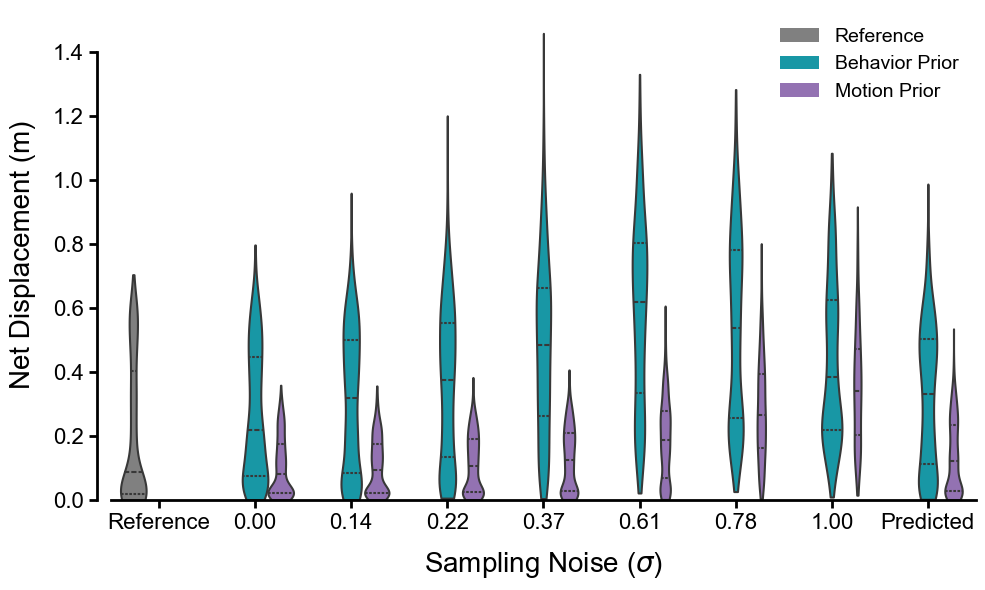

In [19]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)
color_ref = (0.5, 0.5, 0.5)

# Build categorical sigma labels matching the KID plots
sigma_label_map = {
    "deterministic": "0.00",
    "std=0.135": "0.14",
    "std=0.223": "0.22",
    "std=0.368": "0.37",
    "std=0.607": "0.61",
    "std=0.779": "0.78",
    "std=1.000": "1.00",
    "predicted": "Predicted",
}

violin_df = disp_df[disp_df["label"].isin(sigma_label_map)].copy()
violin_df["sigma"] = violin_df["label"].map(sigma_label_map)

# Add reference as a violin on the left
if original_disp is not None:
    ref_rows = pd.DataFrame({
        "method": "Reference",
        "sigma": "Reference",
        "displacement": original_disp,
    })
    violin_df = pd.concat([ref_rows, violin_df], ignore_index=True)

sigma_order = ["Reference", "0.00", "0.14", "0.22", "0.37", "0.61", "0.78", "1.00", "Predicted"]
violin_df["sigma"] = pd.Categorical(violin_df["sigma"], categories=sigma_order, ordered=True)

fig, ax = plt.subplots(figsize=(10, 6))

palette = {LABEL_A: color_a, LABEL_B: color_b, "Reference": color_ref}

sns.violinplot(
    data=violin_df,
    x="sigma",
    y="displacement",
    hue="method",
    inner="quart",
    palette=palette,
    linewidth=1.5,
    order=sigma_order,
    cut=0,
    ax=ax,
)

ax.set_ylim(0, None)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=20, labelpad=12)
ax.set_ylabel("Net Displacement (m)", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
legend = ax.legend(fontsize=14, frameon=False)
for handle in legend.legend_handles:
    handle.set_edgecolor("none")

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))

yticks = ax.get_yticks()
ylim = ax.get_ylim()
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]
if yticks:
    ax.spines["left"].set_bounds(yticks[0], yticks[-1])

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

SAVE_DIR.mkdir(parents=True, exist_ok=True)
disp_violin_save = f"{SAVE_NAME}_net_displacement_violin"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{disp_violin_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / disp_violin_save}.[pdf|svg|png]")

plt.show()

## Proportion of Time Below Root Height

ECDF of root z-position across all rollouts, showing what fraction of time
the rodent spends below each height.

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_z_height_ecdf.[pdf|svg|png]


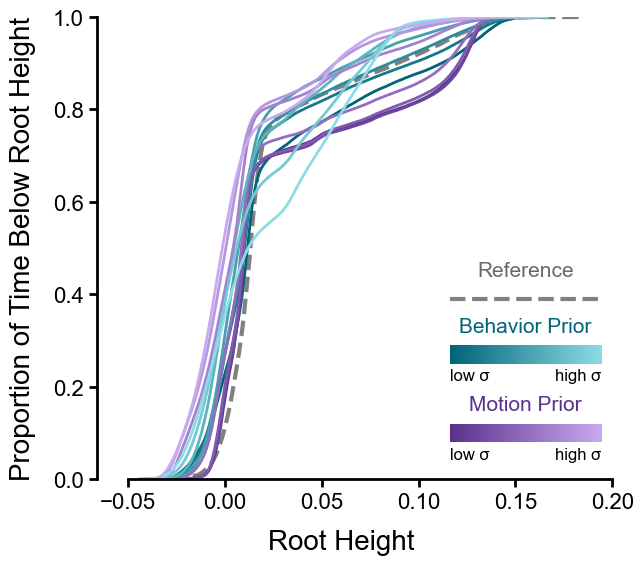

In [6]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Reference
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Reference", ax=ax)

# Get sorted noise levels for alpha mapping
noise_levels = sorted(set(
    parse_dataset_name(name, logvars_a)["sort_key"]
    for name in qpos_a
    if np.isfinite(parse_dataset_name(name, logvars_a)["sort_key"])
))

# Sequential colormaps per method: dark \u2192 light within each hue family
color_a_dark = (0 / 255, 100 / 255, 120 / 255)   # dark teal
color_a_light = (140 / 255, 220 / 255, 230 / 255) # light cyan
color_b_dark = (90 / 255, 50 / 255, 140 / 255)    # dark purple
color_b_light = (200 / 255, 170 / 255, 240 / 255) # light lavender

cmap_a = LinearSegmentedColormap.from_list('scamper', [color_a_dark, color_a_light])
cmap_b = LinearSegmentedColormap.from_list('pulse', [color_b_dark, color_b_light])

n_levels = len(noise_levels)
fracs = [i / max(n_levels - 1, 1) for i in range(n_levels)]

# Draw individual curves per noise level
for noise, frac in zip(noise_levels, fracs):
    # Behavior Prior
    for name, qpos in qpos_a.items():
        info = parse_dataset_name(name, logvars_a)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_a(frac), linewidth=2, ax=ax,
                         label="_nolegend_")
    # Motion Prior
    for name, qpos in qpos_b.items():
        info = parse_dataset_name(name, logvars_b)
        if info["sort_key"] == noise:
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=cmap_b(frac), linewidth=2, ax=ax,
                         label="_nolegend_")

ax.set_xlabel("Root Height", fontsize=20, labelpad=12)
ax.set_ylabel("Proportion of Time Below Root Height", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)


# Legend: colorbars + labels using ax.text() for stable PDF rendering
cbar_w = 0.28
cbar_h = 0.04
cbar_x = 1.0 - cbar_w - 0.02
base_y = 0.08
y_positions = [base_y, base_y + 0.17]  # Motion Prior, Behavior Prior
ref_offset = 0.12  # smaller gap Reference-Behavior Prior

legend_items = [
    (cmap_b, LABEL_B, color_b_dark),
    (cmap_a, LABEL_A, color_a_dark),
]

for i, (cmap, label, title_color) in enumerate(legend_items):
    y = y_positions[i]
    # Gradient bar
    cbar_ax = ax.inset_axes([cbar_x, y, cbar_w, cbar_h])
    gradient = np.linspace(0, 1, 256).reshape(1, -1)
    cbar_ax.imshow(gradient, aspect="auto", cmap=cmap)
    cbar_ax.set_axis_off()
    # Labels using ax.text (axes coords)
    ax.text(cbar_x + cbar_w / 2, y + cbar_h + 0.02, label,
            transform=ax.transAxes, fontsize=15, color=title_color,
            ha="center", va="bottom")
    ax.text(cbar_x, y - 0.01, "low \u03c3",
            transform=ax.transAxes, fontsize=12, ha="left", va="top")
    ax.text(cbar_x + cbar_w, y - 0.01, "high \u03c3",
            transform=ax.transAxes, fontsize=12, ha="right", va="top")

# Reference entry
ref_y = y_positions[1] + ref_offset
ref_ax = ax.inset_axes([cbar_x, ref_y, cbar_w, cbar_h])
ref_ax.plot([0, 1], [0.5, 0.5], color="gray", linestyle="--", linewidth=3,
            transform=ref_ax.transAxes, clip_on=False)
ref_ax.set_axis_off()
ax.text(cbar_x + cbar_w / 2, ref_y + cbar_h + 0.02, "Reference",
        transform=ax.transAxes, fontsize=15, color="dimgray",
        ha="center", va="bottom")

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["left"].set_position(("axes", 0.05))
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)


# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_z_height_ecdf_predicted.[pdf|svg|png]


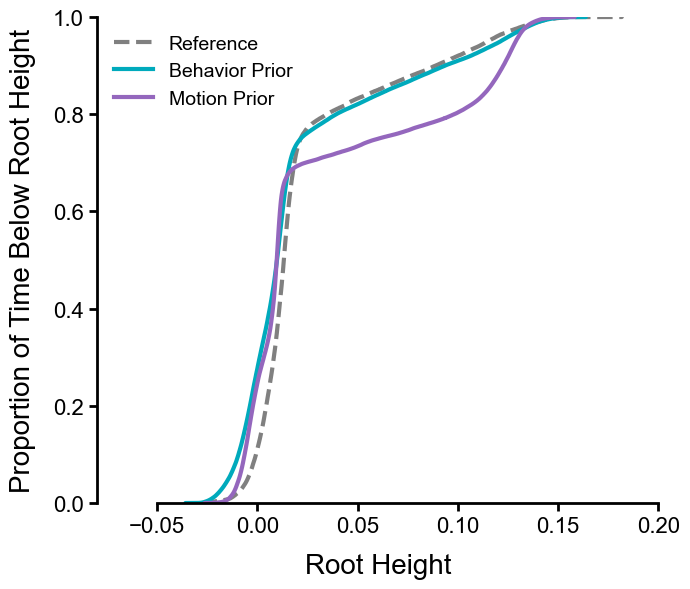

In [7]:
matplotlib.rcParams["font.family"] = "Arial"

color_a = (0 / 255, 170 / 255, 188 / 255)
color_b = (148 / 255, 103 / 255, 189 / 255)

fig, ax = plt.subplots(figsize=(7, 6))

# Reference
if original_qpos is not None:
    z_ref = original_qpos[:, :, 2].ravel()
    z_ref = z_ref[z_ref >= -0.05]
    sns.ecdfplot(z_ref, color="gray", linestyle="--", linewidth=3, label="Reference", ax=ax)

# Predicted logvar curves
for method_label, qpos_datasets, logvars, color in [
    (LABEL_A, qpos_a, logvars_a, color_a),
    (LABEL_B, qpos_b, logvars_b, color_b),
]:
    for name, qpos in qpos_datasets.items():
        info = parse_dataset_name(name, logvars)
        if info["label"] == "predicted":
            z = qpos[:, :, 2].ravel()
            z = z[z >= -0.05]
            sns.ecdfplot(z, color=color, linewidth=3, label=method_label, ax=ax)

ax.set_xlabel("Root Height", fontsize=20, labelpad=12)
ax.set_ylabel("Proportion of Time Below Root Height", fontsize=20, labelpad=12)
ax.tick_params(labelsize=16, width=2, length=6)
ax.legend(fontsize=14, frameon=False)

ax.set_xlim(-0.08, 0.20)
ax.set_xticks([-0.05, 0.0, 0.05, 0.10, 0.15, 0.20])

sns.despine(ax=ax)
ax.spines["bottom"].set_bounds(-0.05, 0.20)
ax.spines["left"].set_bounds(0.0, 1.0)

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

plt.tight_layout()

# Save figures
SAVE_DIR.mkdir(parents=True, exist_ok=True)
z_save = f"{SAVE_NAME}_z_height_ecdf_predicted"
for ext in ["pdf", "svg", "png"]:
    fig.savefig(SAVE_DIR / f"{z_save}.{ext}", bbox_inches="tight")
print(f"Saved to {SAVE_DIR / z_save}.[pdf|svg|png]")

plt.show()

## 2D Trajectory Heatmaps

Density heatmaps of all rollout XY trajectories, comparing reference, Behavior Prior, and Motion Prior.
Uses the predicted log-variance rollouts (the most natural sampling mode).
Immediately shows whether the rodent is exploring space vs standing still.

[deterministic] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_deterministic.[pdf|svg|png]


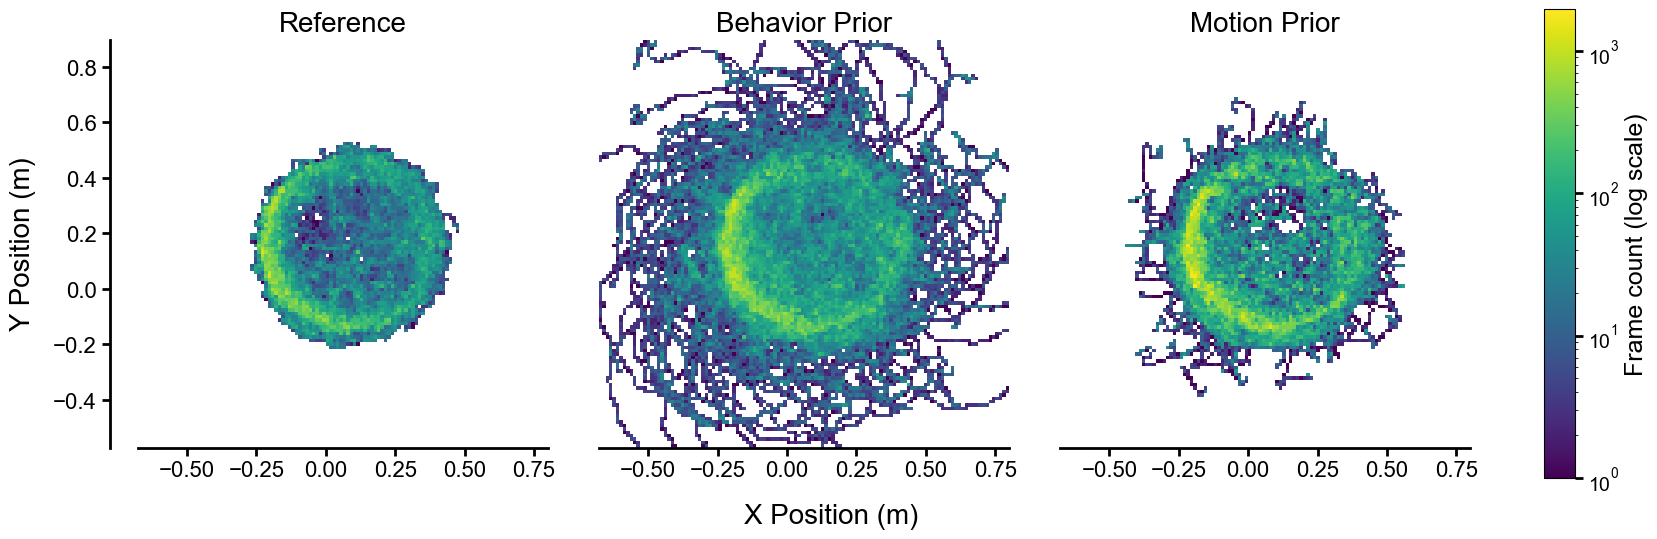

[std=0.135] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std0.135.[pdf|svg|png]


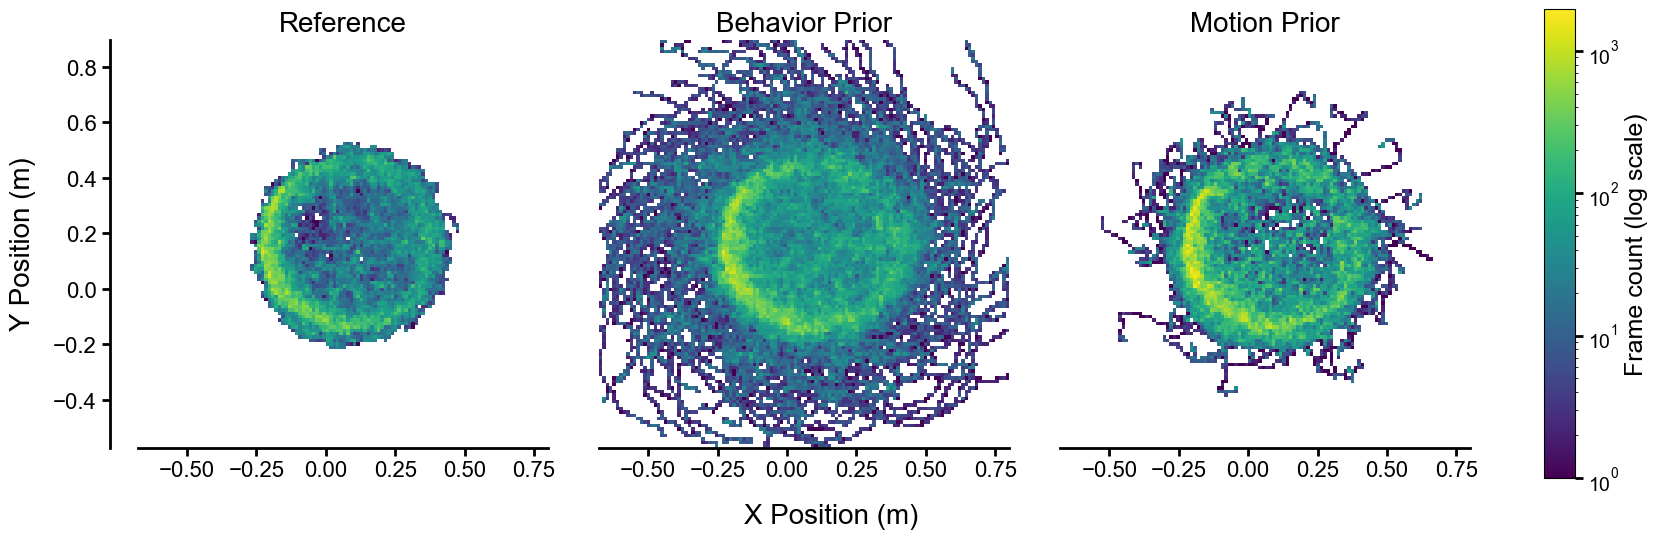

[std=0.223] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std0.223.[pdf|svg|png]


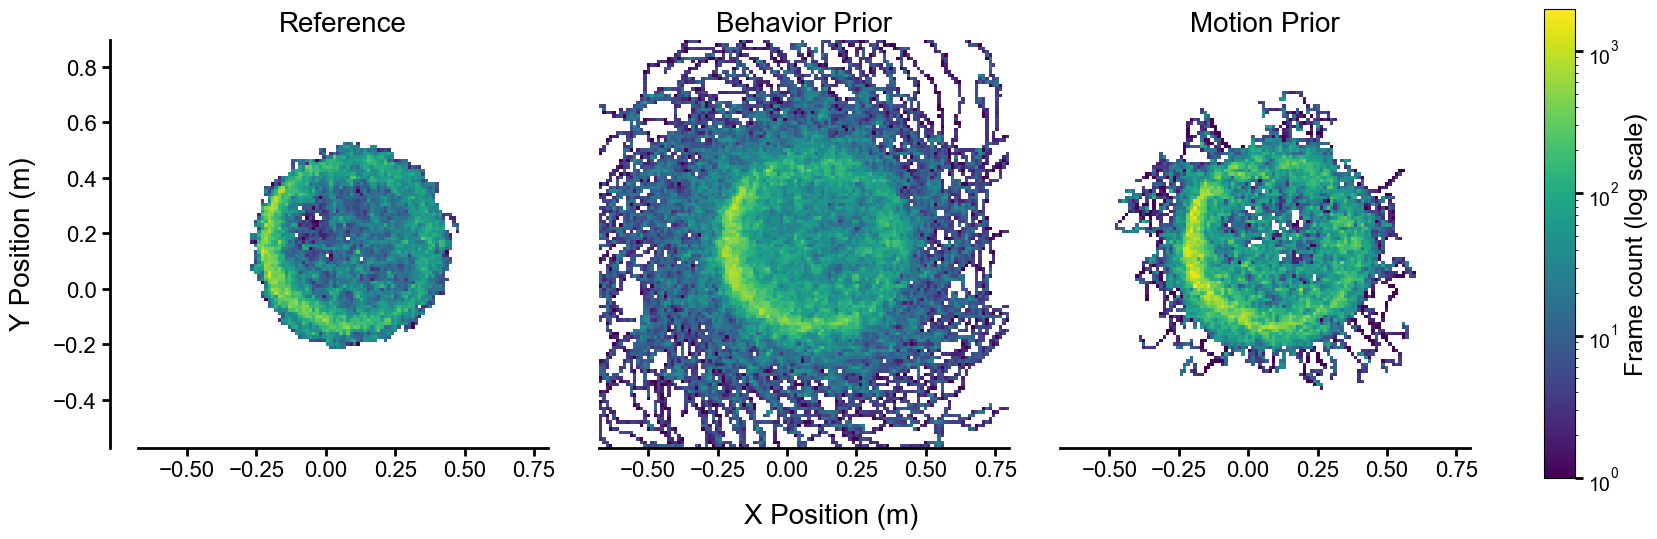

[std=0.368] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std0.368.[pdf|svg|png]


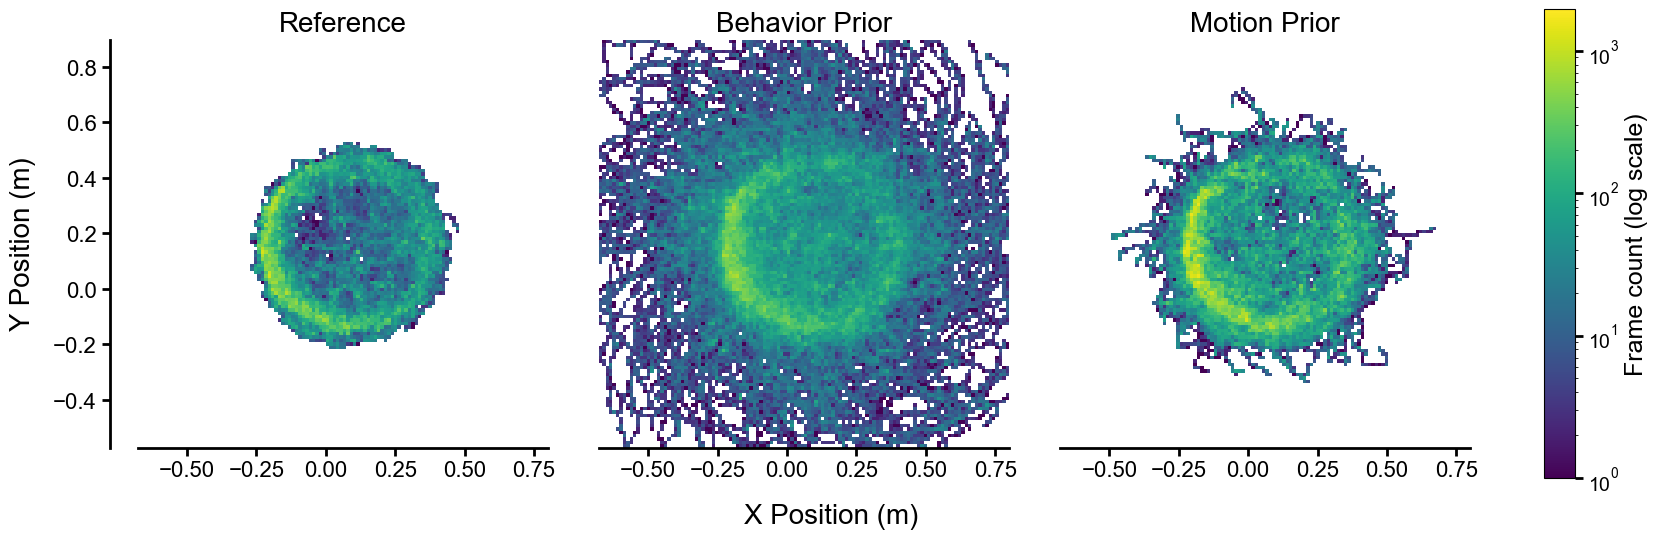

[std=0.607] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std0.607.[pdf|svg|png]


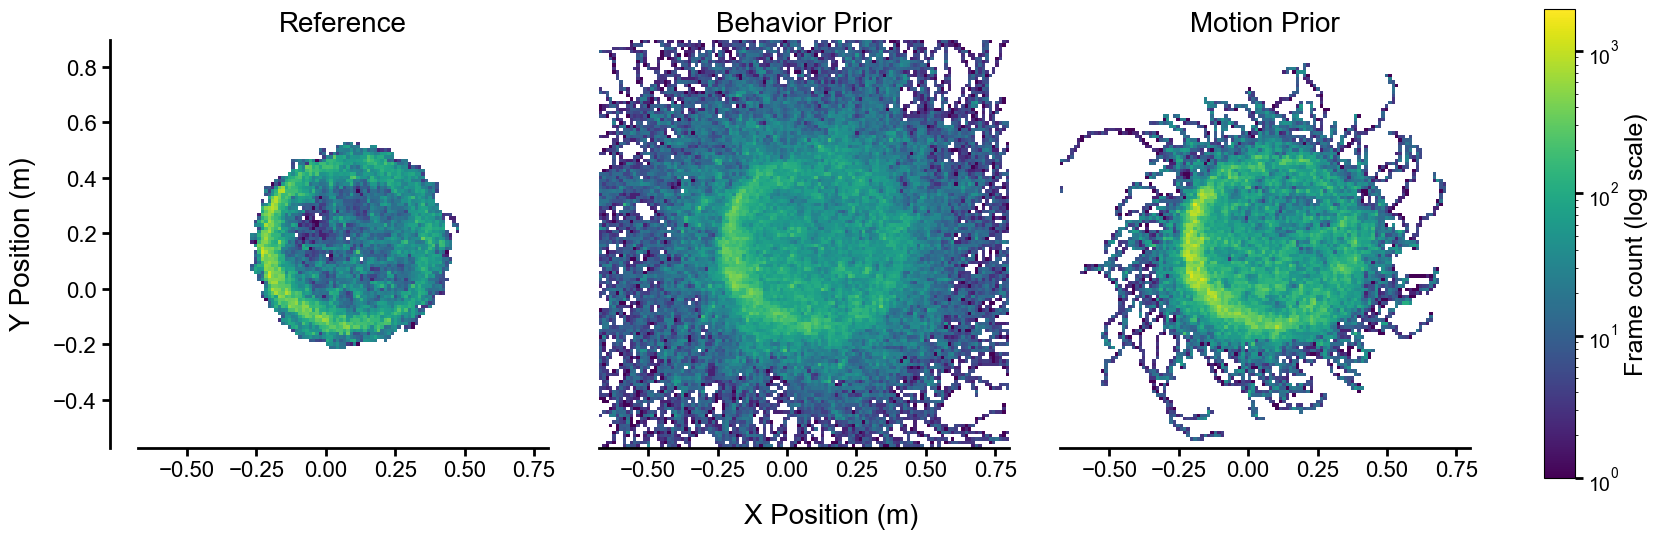

[std=0.779] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std0.779.[pdf|svg|png]


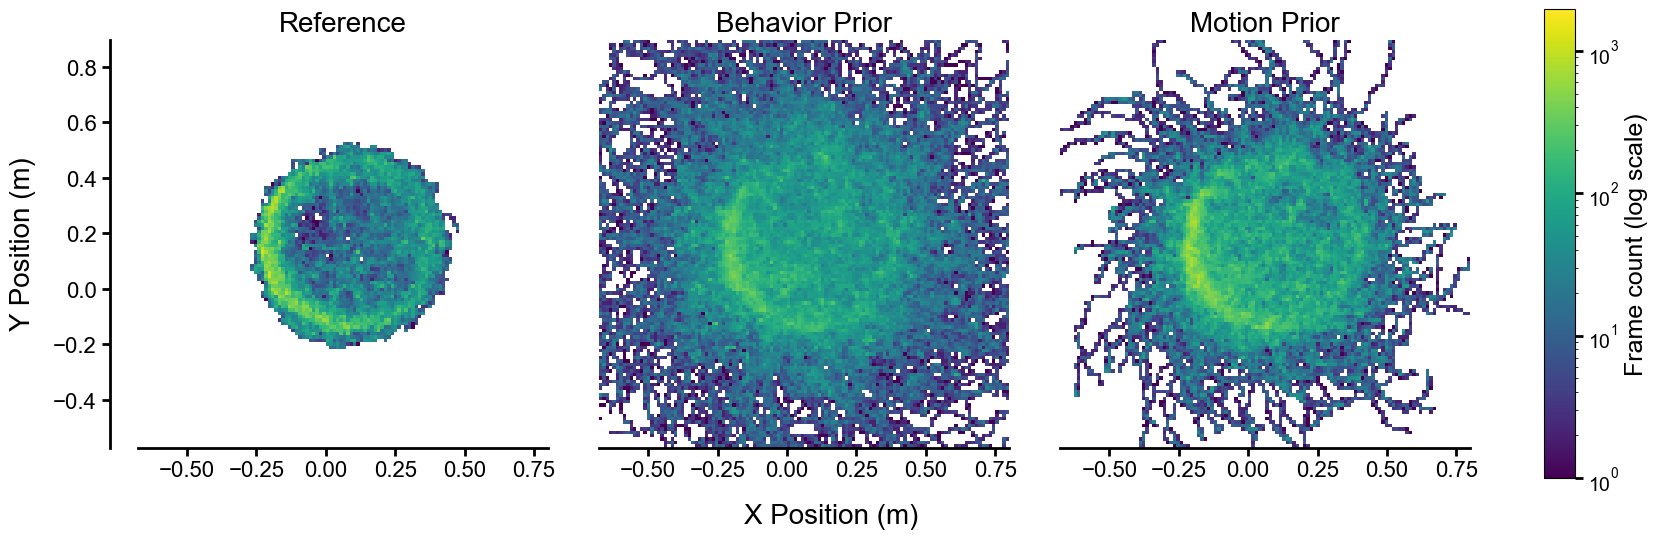

[std=1.000] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_std1.000.[pdf|svg|png]


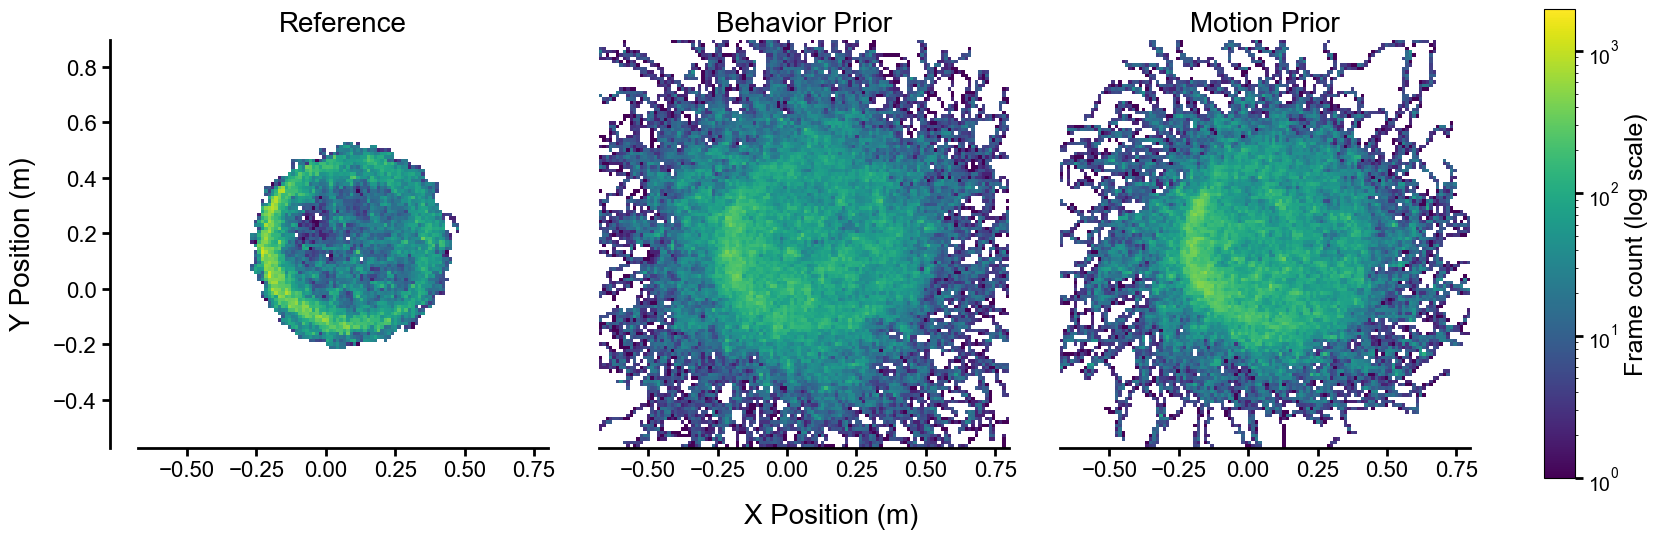

[predicted] Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/prior_rollout_stats_trajectory_heatmap_predicted.[pdf|svg|png]


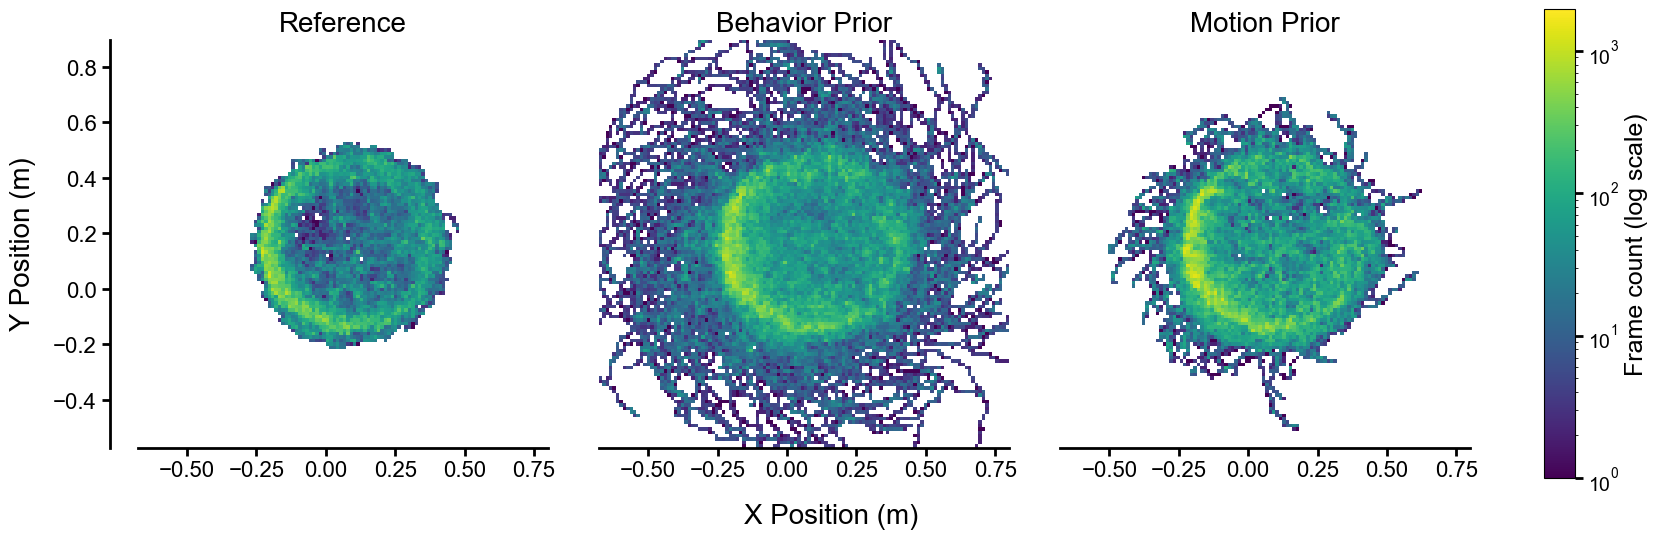

In [33]:
matplotlib.rcParams["font.family"] = "Arial"

# Build list of (noise_label, sort_key, qpos_a, qpos_b)
# Match datasets across methods by parsed label
datasets_by_label = {}
for ds_name, qpos in qpos_a.items():
    if not (ds_name.startswith("prior_") or ds_name.startswith("rgm_")):
        continue
    info = parse_dataset_name(ds_name, logvars_a)
    key = info["label"]
    datasets_by_label.setdefault(key, {"sort_key": info["sort_key"], "label": key})
    datasets_by_label[key]["qpos_a"] = qpos
for ds_name, qpos in qpos_b.items():
    if not (ds_name.startswith("prior_") or ds_name.startswith("rgm_")):
        continue
    info = parse_dataset_name(ds_name, logvars_b)
    key = info["label"]
    datasets_by_label.setdefault(key, {"sort_key": info["sort_key"], "label": key})
    datasets_by_label[key]["qpos_b"] = qpos

# Sort by noise level
sorted_labels = sorted(datasets_by_label.values(), key=lambda d: d["sort_key"])

# Compute shared axis limits across ALL datasets + reference
all_x, all_y = [], []
if original_qpos is not None:
    all_x.append(original_qpos[:, :, 0].ravel())
    all_y.append(original_qpos[:, :, 1].ravel())
for d in sorted_labels:
    for k in ["qpos_a", "qpos_b"]:
        if k in d:
            all_x.append(d[k][:, :, 0].ravel())
            all_y.append(d[k][:, :, 1].ravel())
all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)
pad = 0.15
x_range = (np.percentile(all_x, 1) - pad, np.percentile(all_x, 99) + pad)
y_range = (np.percentile(all_y, 1) - pad, np.percentile(all_y, 99) + pad)

bins = 120

# Precompute all histograms to find shared vmax
def make_hist(qpos):
    x = qpos[:, :, 0].ravel()
    y = qpos[:, :, 1].ravel()
    h, _, _ = np.histogram2d(x, y, bins=bins, range=[x_range, y_range])
    return h

all_hists = []
if original_qpos is not None:
    all_hists.append(make_hist(original_qpos))
for d in sorted_labels:
    for k in ["qpos_a", "qpos_b"]:
        if k in d:
            all_hists.append(make_hist(d[k]))
shared_vmax = max(h.max() for h in all_hists)

# One figure per noise level: Reference | Behavior Prior | Motion Prior
for entry in sorted_labels:
    label = entry["label"]
    panels = []
    if original_qpos is not None:
        panels.append(("Reference", original_qpos))
    if "qpos_a" in entry:
        panels.append((LABEL_A, entry["qpos_a"]))
    if "qpos_b" in entry:
        panels.append((LABEL_B, entry["qpos_b"]))

    ncols = len(panels)
    fig, axes = plt.subplots(
        1, ncols, figsize=(5 * ncols + 1.5, 5),
        constrained_layout=True,
    )
    fig.get_layout_engine().set(wspace=0.08)
    if ncols == 1:
        axes = [axes]

    for ax, (title, qpos) in zip(axes, panels):
        h = make_hist(qpos)
        h_plot = np.ma.masked_where(h.T == 0, h.T)
        im = ax.pcolormesh(
            np.linspace(*x_range, bins + 1),
            np.linspace(*y_range, bins + 1),
            h_plot,
            norm=mcolors.LogNorm(vmin=1, vmax=shared_vmax),
            cmap="viridis",
            rasterized=True,
        )
        ax.set_title(title, fontsize=20, fontweight="bold")
        ax.set_aspect("equal")
        ax.tick_params(labelsize=16, width=2, length=6)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["bottom"].set_linewidth(2)
        ax.spines["left"].set_linewidth(2)

    # Offset left spine on first panel to create gap between x and y spines
    axes[0].spines["left"].set_position(("outward", 20))
    axes[0].set_ylabel("Y Position (m)", fontsize=20, labelpad=12)
    for ax in axes[1:]:
        ax.set_yticklabels([])
        ax.tick_params(axis="y", length=0)
        ax.spines["left"].set_visible(False)

    # Single shared x label centered under all panels
    fig.supxlabel("X Position (m)", fontsize=20, y=-0.06)

    cbar = fig.colorbar(im, ax=axes, label="Frame Count (log scale)", shrink=1.0, aspect=15)
    cbar.ax.tick_params(labelsize=14, width=2, length=6)
    cbar.set_label("Frame count (log scale)", fontsize=18)

    # Save
    safe_label = label.replace("=", "").replace(" ", "_")
    save_base = SAVE_DIR / f"{SAVE_NAME}_trajectory_heatmap_{safe_label}"
    for ext in ["pdf", "svg", "png"]:
        fig.savefig(f"{save_base}.{ext}", dpi=300, bbox_inches="tight")
    print(f"[{label}] Saved to {save_base}.[pdf|svg|png]")

    plt.show()